# Case Study 05 — Malaria classification

**Goal.** Build and *properly evaluate* a classifier that detects malaria
parasites in segmented red-blood-cell images.

Beyond the modelling itself, this case study is about how evaluation can lie
to you:

- **patient-level leakage**: multiple cells come from the same patient's
  smear, and must never straddle the train/test boundary;
- **accuracy worship**: in a medical screening context, the false-negative
  cost dominates — so we also tune the decision threshold;
- **one number is never enough**: confusion matrix, ROC, and an actual look
  at the misclassified images.

Dataset: the NIH malaria cell images (`Data/cell_images`,
[dataset page](https://www.tensorflow.org/datasets/catalog/malaria)).
Class04 introduces ensemble *theory*; here we use it end-to-end.

## Load and label the data

PNG paths are collected per class, labelled, and — crucially — the **patient
code** is parsed out of the filename (`C100` in `C100P61ThinF_IMG_...png`).
Keep this column in mind: it drives the leakage-safe split below.

In [1]:
%matplotlib inline
import glob
import statistics

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

infected = '../../Data/cell_images/Parasitized'
healthy = '../../Data/cell_images/Uninfected'

infected_files = sorted(glob.glob(infected + '/*.png'))
healthy_files = sorted(glob.glob(healthy + '/*.png'))
print(len(infected_files), 'parasitised vs', len(healthy_files), 'uninfected images')

files_df = pd.DataFrame({
    'img': infected_files + healthy_files,
    'malaria': [1] * len(infected_files) + [0] * len(healthy_files)
})
files_df['patient'] = files_df['img'].str.extract(r'/(C\d+)', expand=False)
files_df = files_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 2000-image subset keeps CPU training time modest; set to len(files_df)
# (about 27k images) for the real experiment
files_df = files_df.iloc[:2000].copy()
print(files_df['malaria'].value_counts())
print('distinct patients in subset:', files_df['patient'].nunique())

I0000 00:00:1792730223.306896 2141246 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792730223.376963 2141246 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792730226.022623 2141246 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


13779 parasitised vs 13779 uninfected images
malaria
1    1030
0     970
Name: count, dtype: int64
distinct patients in subset: 200


## Look at the data first

Always render a handful of examples before modelling — a stray labelling or
loading bug is far cheaper to catch by eye than by debugging a loss curve.

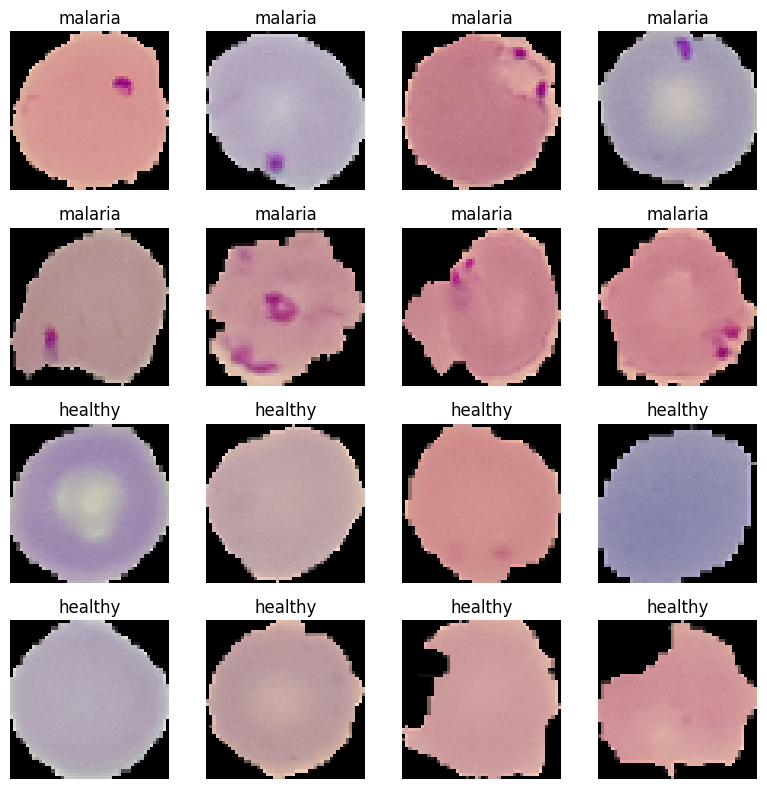

In [2]:
def get_data(paths):
    # read -> RGB -> 50x50 resize; unreadable files are skipped
    data, kept = [], []
    for i, path in enumerate(paths):
        img = cv2.imread(path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # cv2 loads BGR
        data.append(cv2.resize(img, (50, 50), interpolation=cv2.INTER_CUBIC))
        kept.append(i)
    return np.asarray(data), np.asarray(kept)

# montage of 8 parasitised / 8 uninfected
sample_idx = np.r_[files_df.index[files_df.malaria == 1][:8],
                   files_df.index[files_df.malaria == 0][:8]]
X_sample, _ = get_data(files_df.loc[sample_idx, 'img'].values)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for ax, img, lab in zip(axes.flat, X_sample, [1]*8 + [0]*8):
    ax.imshow(img)
    ax.set_title('malaria' if lab else 'healthy')
    ax.axis('off')
fig.tight_layout()
plt.savefig('sample.png', bbox_inches='tight')
plt.show()

## Arrays in, leakage-safe split

We normalise pixel values to [0, 1] (divide by 255) and then split — but
**not randomly**. Cells from the same patient's smear share staining,
background and camera conditions; a random split puts near-duplicates of the
*same smear* on both sides of the boundary, and the model can memorise the
smear rather than learn malaria. `GroupShuffleSplit` keeps all of a
patient's cells together on one side — 60 % train / 20 % validation /
20 % test by patient:

In [3]:
X, kept = get_data(files_df['img'].values)
X = X.astype('float32') / 255.0
y = files_df['malaria'].values[kept]
groups = files_df['patient'].values[kept]
print('X:', X.shape, 'positives:', y.sum())

X: (2000, 50, 50, 3) positives: 1030


In [4]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(test_size=0.4, random_state=42)
tr, tmp = next(gss.split(X, y, groups))
gss2 = GroupShuffleSplit(test_size=0.5, random_state=42)
va, te = next(gss2.split(X[tmp], y[tmp], groups[tmp]))

X_train, X_val, X_test = X[tr], X[tmp][va], X[tmp][te]
y_train, y_val, y_test = y[tr], y[tmp][va], y[tmp][te]
print(f'train {len(X_train)}, val {len(X_val)}, test {len(X_test)}')
print('no patient appears in two splits:',
      len(set(groups[tr]) & set(groups[tmp][te])) == 0)

train 1267, val 353, test 380
no patient appears in two splits: True


## A cheap baseline first

Before any deep learning, fit a **logistic regression on the raw pixel
values**. It trains in seconds and sets the bar a CNN must clear. (It will
also power the leakage demonstration below, because it retrains instantly.)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score)

def report(y_true, y_pred, label=''):
    print(f'{label:<16s} acc={accuracy_score(y_true, y_pred):.3f} '
          f'prec={precision_score(y_true, y_pred):.3f} '
          f'rec={recall_score(y_true, y_pred):.3f} '
          f'f1={f1_score(y_true, y_pred):.3f}')

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train.reshape(len(X_train), -1), y_train)
report(y_test, baseline.predict(X_test.reshape(len(X_test), -1)),
       'logreg baseline')

logreg baseline  acc=0.608 prec=0.619 rec=0.529 f1=0.571


## The leakage demonstration

How much does the grouping actually change the verdict? Re-fit the same
baseline with the naive random split that Class05's predecessor used, and
compare. (We demonstrate with the baseline because it retrains instantly;
CNNs would show the same direction of effect, just slower.)

In [6]:
from sklearn.model_selection import train_test_split

Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(
    X.reshape(len(X), -1), y, test_size=0.2, random_state=42, stratify=y)
naive = LogisticRegression(max_iter=1000).fit(Xn_tr, yn_tr)

acc_naive = accuracy_score(yn_te, naive.predict(Xn_te))
acc_grouped = accuracy_score(y_test, baseline.predict(X_test.reshape(len(X_test), -1)))
print(f'accuracy evaluated with a NAIVE random split : {acc_naive:.3f}')
print(f'accuracy evaluated with a GROUPED split      : {acc_grouped:.3f}')
print(f'naive-evaluation optimism                    : '
      f'{100 * (acc_naive - acc_grouped):.1f} points')

accuracy evaluated with a NAIVE random split : 0.657
accuracy evaluated with a GROUPED split      : 0.608
naive-evaluation optimism                    : 5.0 points


The naive number is the one that would make it into an over-eager report;
the grouped number is the one you should believe when the model meets **new
patients**. Whenever samples are naturally clustered (same patient, same
site, same batch), split by the cluster — `GroupShuffleSplit` is the
one-line switch.

## The CNN

The architecture mirrors Class04 (three conv blocks: 16/16/32 filters with
2×2 pooling, dense 32, dropout 0.5, sigmoid head) — small enough to train on
CPU in minutes. The loss is binary crossentropy, the natural choice for a
sigmoid probability head.

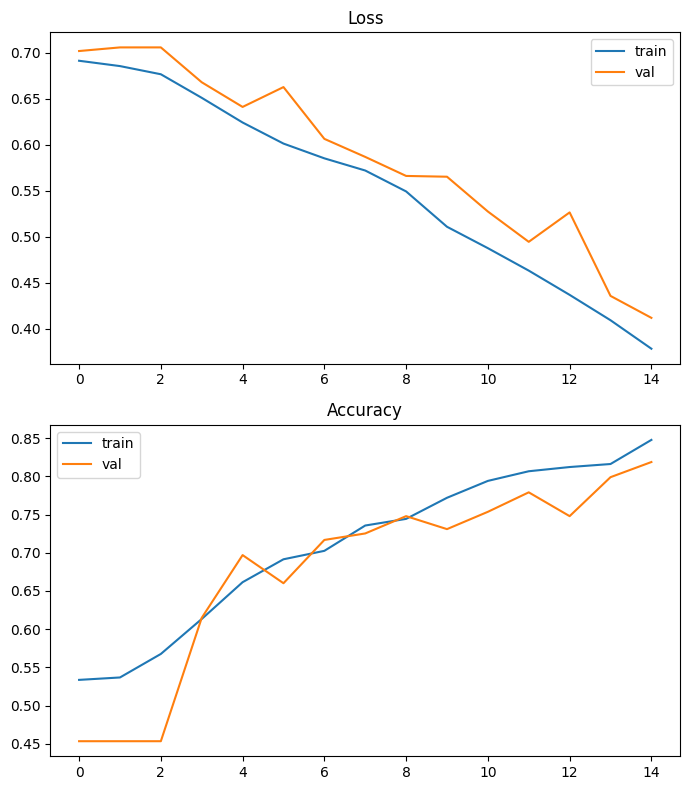

In [7]:
from tensorflow.keras.layers import (Conv2D, Dense, Dropout, Flatten,
                                     MaxPooling2D)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

def build_cnn(width=1.0):
    # three conv blocks from Class04, widths scaled by `width`
    w = lambda n: max(4, int(n * width))
    model = Sequential([
        tf.keras.Input(shape=(50, 50, 3)),
        Conv2D(w(16), 3, activation='relu'),
        MaxPooling2D(2),
        Conv2D(w(16), 3, activation='relu'),
        MaxPooling2D(2),
        Conv2D(w(32), 3, activation='relu'),
        MaxPooling2D(2),
        Flatten(),
        Dense(w(32), activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

cnn = build_cnn()
history = cnn.fit(X_train, y_train, batch_size=64, epochs=15, shuffle=True,
                  validation_data=(X_val, y_val), verbose=0)

fig, axes = plt.subplots(2, 1, figsize=(7, 8))
for ax, (tr_curve, va_curve), title in zip(
        axes, [('loss', 'val_loss'), ('accuracy', 'val_accuracy')],
        ['Loss', 'Accuracy']):
    ax.set_title(title)
    ax.plot(history.history[tr_curve], label='train')
    ax.plot(history.history[va_curve], label='val')
    ax.legend()
fig.tight_layout()
plt.savefig('accuracy_loss.png', bbox_inches='tight')
plt.show()

## Full evaluation — more than accuracy

On the **test** set we look at:

- accuracy / precision / recall / f1 (definitions from Class04: accuracy is
  the fraction correct; f1 is the *harmonic mean* of precision and recall);
- the **confusion matrix** — where exactly errors live;
- the **ROC curve and AUC** — performance across *all* decision thresholds,
  not just the default 0.5.

CNN @0.5         acc=0.837 prec=0.919 rec=0.733 f1=0.815
ROC AUC: 0.937


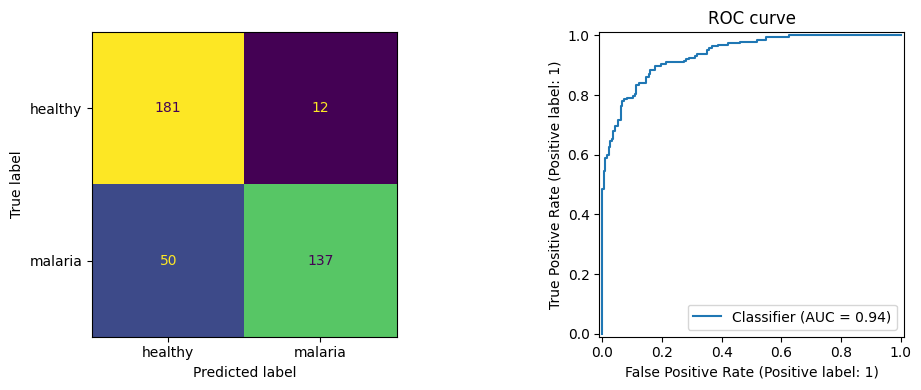

In [8]:
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
                             confusion_matrix, roc_auc_score)

proba_test = cnn.predict(X_test, verbose=0).ravel()
pred_test = (proba_test > 0.5).astype(int)
report(y_test, pred_test, 'CNN @0.5')
print('ROC AUC:', round(roc_auc_score(y_test, proba_test), 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=['healthy', 'malaria']).plot(
                           ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1])
axes[1].set_title('ROC curve')
fig.tight_layout()
plt.show()

## Tuning the decision threshold

The 0.5 cutoff is a convention, not a law. In a **screening** context, a
false negative (missed malaria) is far costlier than a false positive
(confirmatory test later). Sweep the threshold and watch the precision/recall
see-saw:

In [9]:
for thr in (0.3, 0.5, 0.7):
    report(y_test, (proba_test > thr).astype(int), f'CNN @{thr}')

CNN @0.3         acc=0.847 prec=0.809 rec=0.904 f1=0.854
CNN @0.5         acc=0.837 prec=0.919 rec=0.733 f1=0.815
CNN @0.7         acc=0.776 prec=0.981 rec=0.556 f1=0.710


Lowering the threshold to 0.3 typically buys several recall points (fewer
missed cases) at a modest precision cost — often the right trade for
screening. The important habit is making the threshold an **explicit, argued
choice** rather than an accident of the default.

## Look at the failures

A grid of hard misclassifications usually tells you more than any metric —
here, the false negatives (missed parasites) and false positives:

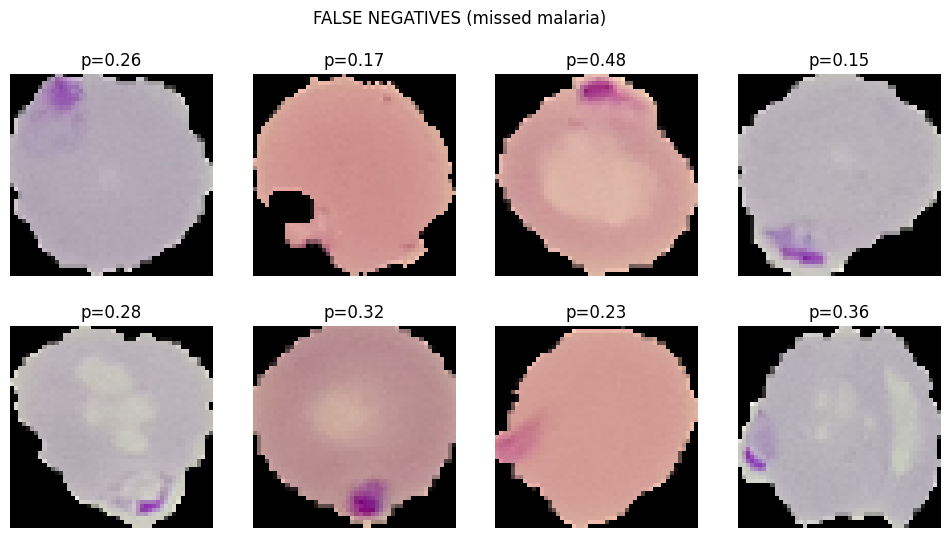

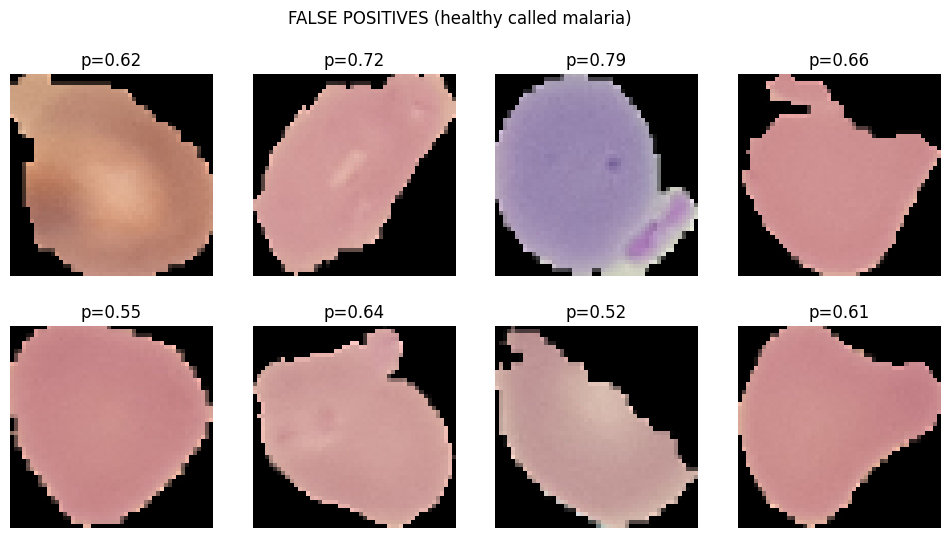

In [10]:
def show_errors(mask, title, k=8):
    idx = np.flatnonzero(mask)[:k]
    if len(idx) == 0:
        print(title, ': none')
        return
    cols = min(4, len(idx))
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes_flat = np.atleast_1d(axes).flat
    for ax, i in zip(axes_flat, idx):
        ax.imshow(X_test[i])
        ax.set_title(f'p={proba_test[i]:.2f}')
        ax.axis('off')
    for ax in axes_flat[len(idx):]:
        ax.axis('off')
    fig.suptitle(title)
    plt.show()

show_errors((pred_test == 0) & (y_test == 1), 'FALSE NEGATIVES (missed malaria)')
show_errors((pred_test == 1) & (y_test == 0), 'FALSE POSITIVES (healthy called malaria)')

## Ensemble the CNNs (soft + hard voting)

Three width variants (1×, 2×, 3×) trained on the same data, combined by
**soft voting** (average the probabilities) and **hard voting** (majority
class — `statistics.mode` is safe for three members on two classes; with an
even member count you would need a tie rule). Compare every member against
both votes on the test set:

In [11]:
models = {'1x': cnn, '2x': build_cnn(2.0), '3x': build_cnn(3.0)}
for name in ('2x', '3x'):
    models[name].fit(X_train, y_train, batch_size=64, epochs=15,
                     shuffle=True, validation_data=(X_val, y_val), verbose=0)

member_probas, member_preds = {}, {}
for name, m in models.items():
    member_probas[name] = m.predict(X_test, verbose=0).ravel()
    member_preds[name] = (member_probas[name] > 0.5).astype(int)
    report(y_test, member_preds[name], f'member {name}')

soft_proba = np.mean(list(member_probas.values()), axis=0)
report(y_test, (soft_proba > 0.5).astype(int), 'ENSEMBLE soft')
hard = np.array([statistics.mode(votes)
                 for votes in zip(*member_preds.values())])
report(y_test, hard, 'ENSEMBLE hard')

member 1x        acc=0.837 prec=0.919 rec=0.733 f1=0.815


member 2x        acc=0.942 prec=0.966 rec=0.914 f1=0.940


member 3x        acc=0.955 prec=0.967 rec=0.941 f1=0.954
ENSEMBLE soft    acc=0.945 prec=0.966 rec=0.920 f1=0.942
ENSEMBLE hard    acc=0.945 prec=0.966 rec=0.920 f1=0.942


## What to take away

- **Group your splits when samples cluster** (patients, sites, batches) —
  the naive split politely overstated our accuracy.
- **Report the metric that matches the cost**: recall-forward for screening,
  and an explicitly chosen threshold, not the default 0.5.
- **One number is never the whole story** — confusion matrix, ROC, and a
  grid of actual misclassifications.
- **Ensembles are insurance**: the vote matches the best member here, and
  protects you when a single run is unlucky (see Class04 for the theory).
- Next steps if you continue: data augmentation (rotations/flips are almost
  free accuracy at 2k images), transfer learning (a pretrained backbone
  dominates hand-rolled CNNs at this scale), and using the full ~27k-image
  dataset past the teaching subset.